In [ ]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import myutils

workspace,experiment=myutils.workspace()
from __future__ import annotations

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

In [2]:
# PATHS ---------------------------------------------------------------------- #
adata_file = experiment/'results/pbmc3k_raw.h5ad'
assert adata_file.exists()

In [3]:
adata = ad.read_h5ad(adata_file)

In [4]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

# QC Metrics

In [5]:
# SETTINGS ------------------------------------------------------------------- #
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80,facecolor='white', frameon=False)

In [6]:
# DEFINE GENES --------------------------------------------------------------- #
# mitochondrial genes
genes_mt = adata.var_names.str.startswith("MT-")
adata.var["mt"] = genes_mt
# ribosomal genes
genes_ribo = adata.var_names.str.startswith(("RPCS","RPL"))
adata.var["ribo"] = genes_ribo
# hemoglobin genes.
genes_hb = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)")
adata.var["hb"] = genes_hb
sum(genes_mt),sum(genes_ribo),sum(genes_hb)

(np.int64(13), np.int64(56), np.int64(10))

In [7]:
# CALCULATE QUALITY CONTROL METRICS ------------------------------------------ #
# qc_vars: Keys for boolean columns of .var which identify variables you could want to control for 
# percent_top: List of ranks (where genes are ranked by expression) at which the cumulative proportion of expression will be reported as a percentage. (default: (50, 100, 200, 500))
# log1p: Set to False to skip computing log1p transformed annotations.
# ---------------------------------------------------------------------------- #

sc.pp.calculate_qc_metrics(
    adata, 
    qc_vars=["mt", "ribo", "hb"], 
    inplace=True, 
    percent_top=[20], 
    # percent_top=None, 
    log1p=True
)
print(adata)
list(adata.obs.columns)

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)


['n_genes_by_counts',
 'log1p_n_genes_by_counts',
 'total_counts',
 'log1p_total_counts',
 'pct_counts_in_top_20_genes',
 'total_counts_mt',
 'log1p_total_counts_mt',
 'pct_counts_mt',
 'total_counts_ribo',
 'log1p_total_counts_ribo',
 'pct_counts_ribo',
 'total_counts_hb',
 'log1p_total_counts_hb',
 'pct_counts_hb']

In [8]:
sc.pp.scrublet(adata)

Running Scrublet
filtered out 19024 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:02)
extracting highly variable genes
    finished (0:00:02)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.25
Detected doublet rate = 1.2%
Estimated detectable doublet fraction = 33.8%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 3.5%
    Scrublet finished (0:00:14)


# Plots

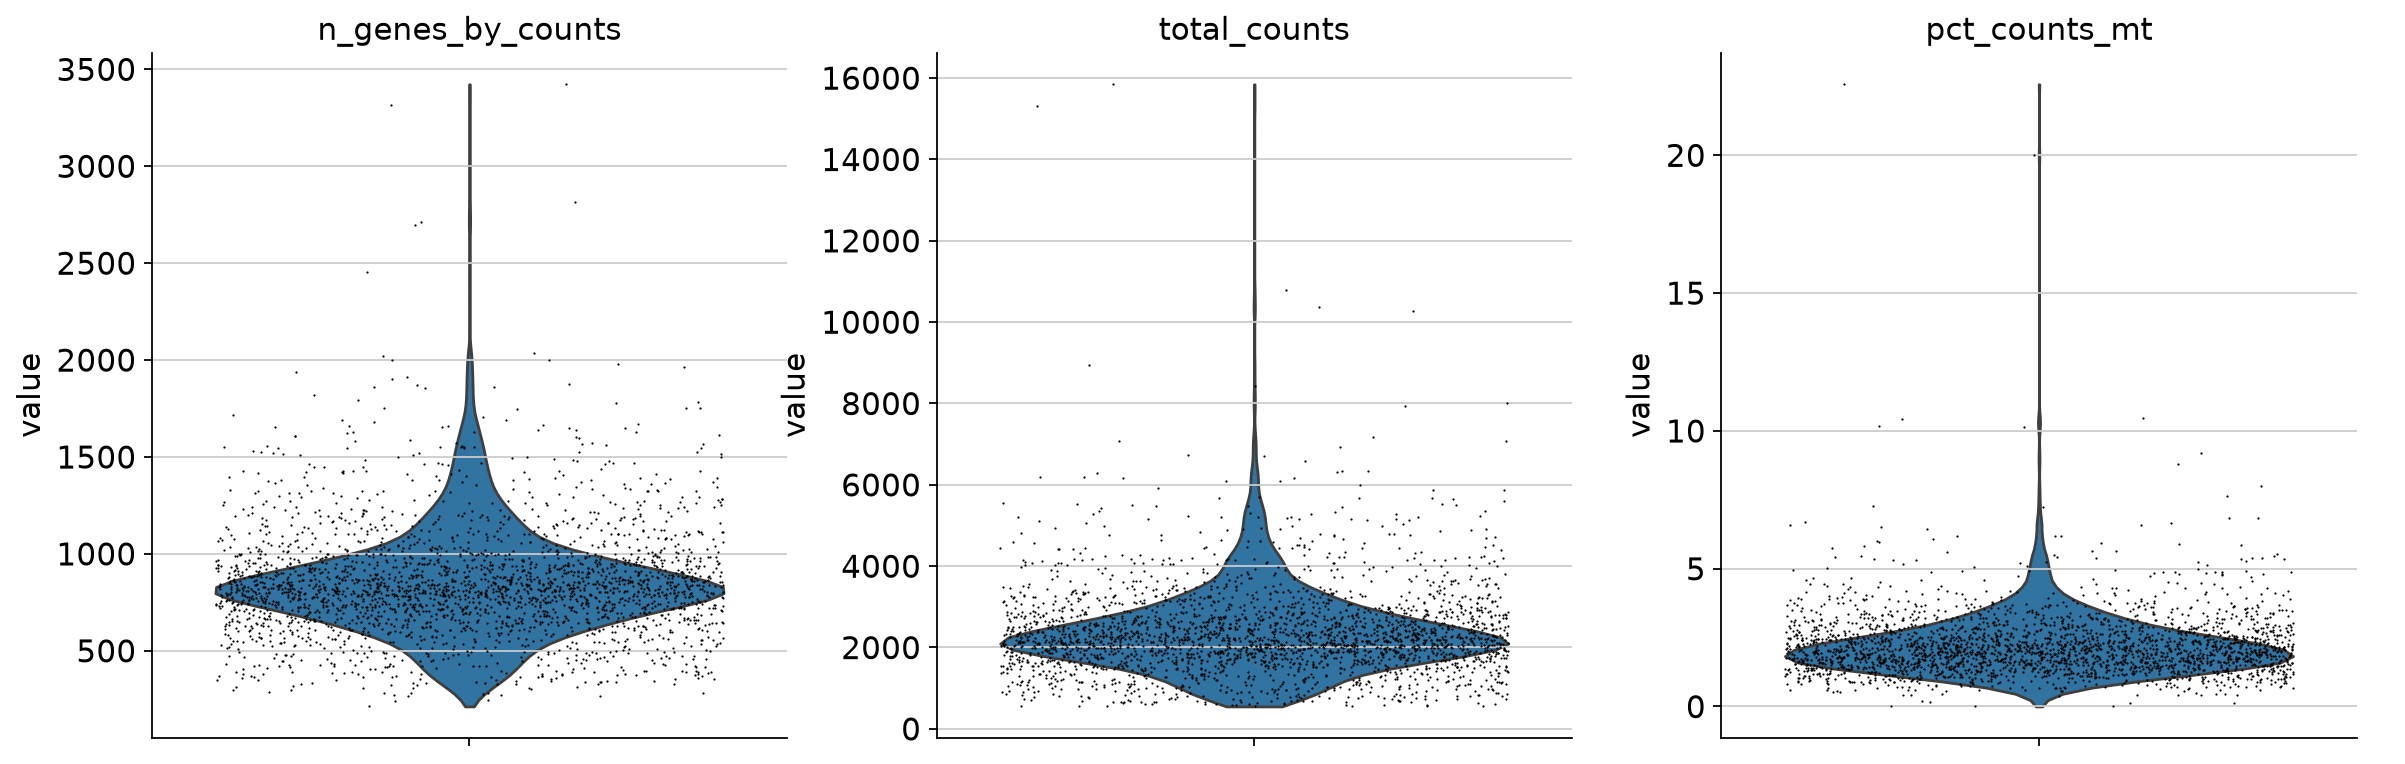

In [9]:
 # COUNT DISTRIBUTIONS -------------------------------------------------------- #
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show=False,
)
plt.savefig(experiment/'figures/qc_metrics/pbmc3k_count_metrics.png')

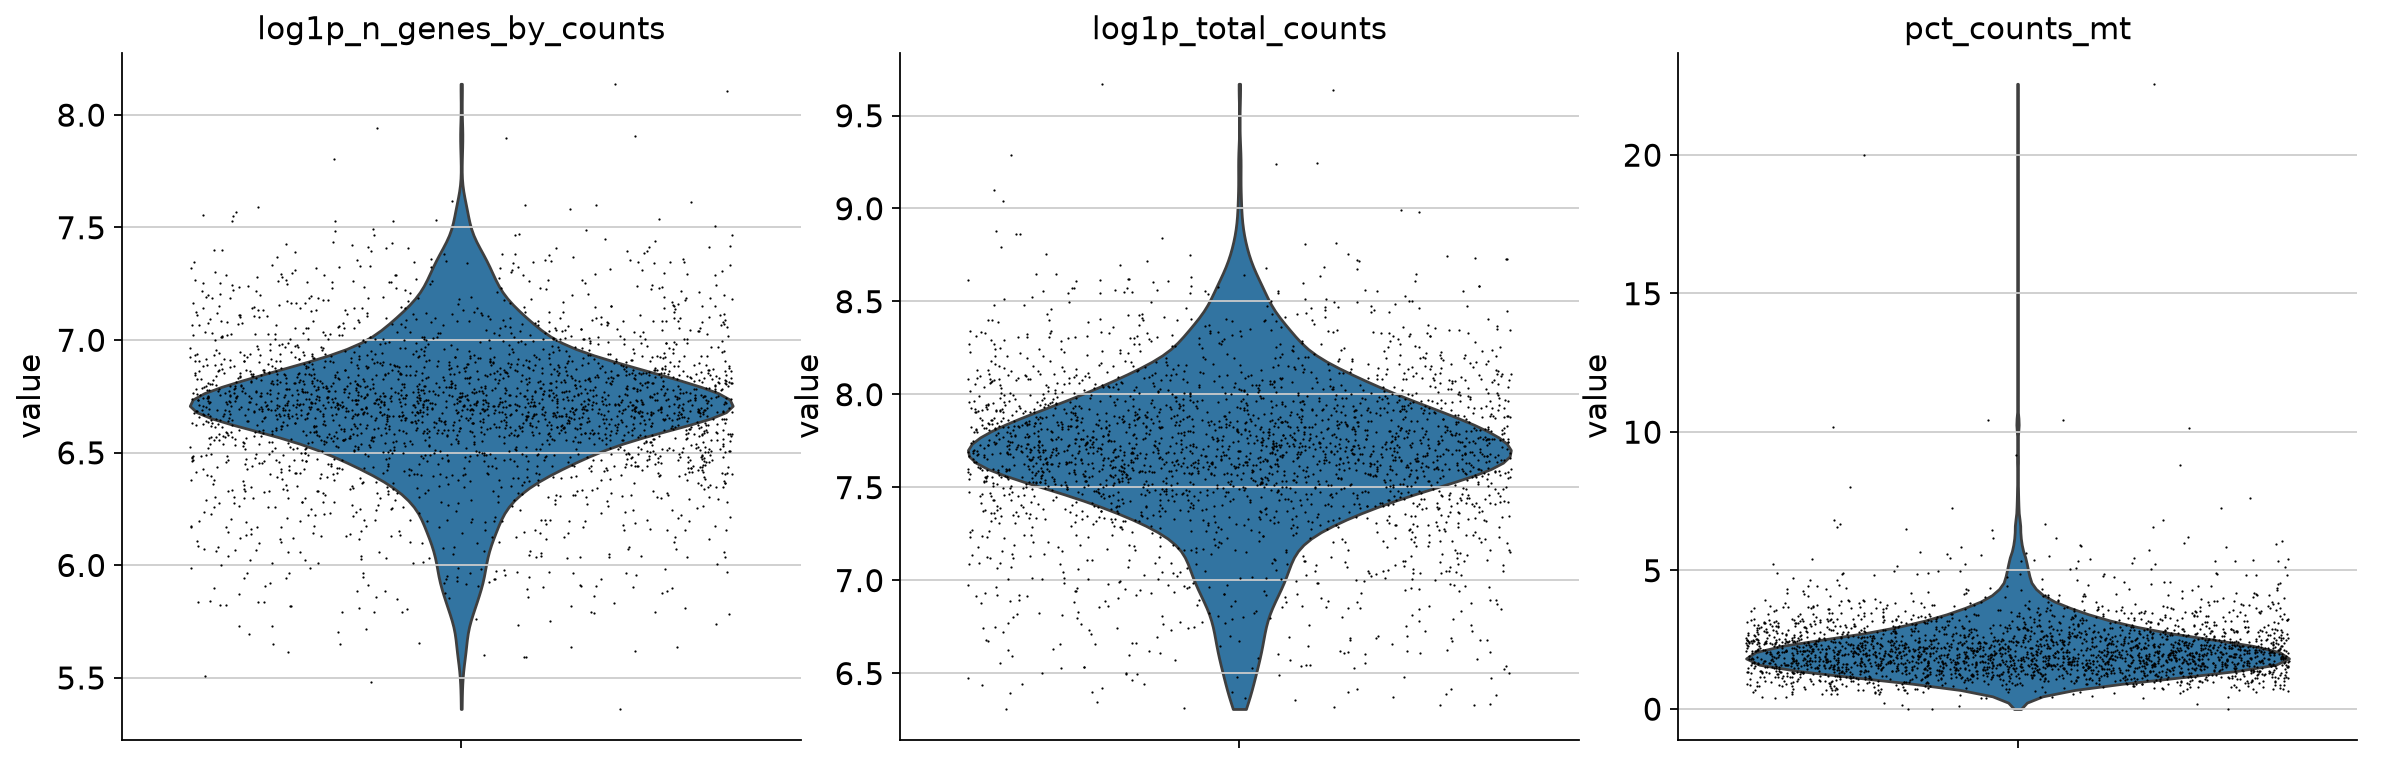

In [10]:
# LOG1P COUNT DISTRIBUTIONS -------------------------------------------------- #
p1 = sc.pl.violin(
    adata,
    ["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show=False,
)
plt.savefig(experiment/'figures/qc_metrics/pbmc3k_log1p_count_metrics.png')
plt.show()

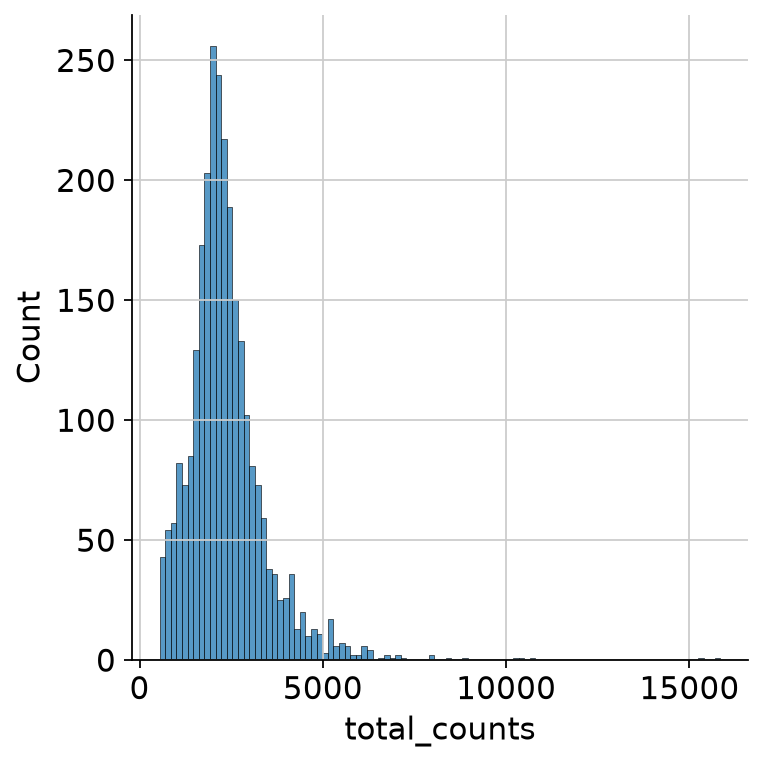

In [11]:
# DISTRIBUTION / HISTOGRAM OF TOTAL COUNTS FOR EACH CELL --------------------- #
# total_counts: total number of counts for a cell (library size)
# ---------------------------------------------------------------------------- #
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
p1.savefig(experiment/'figures/qc_metrics/pbmc3k_total_counts_dist.png')

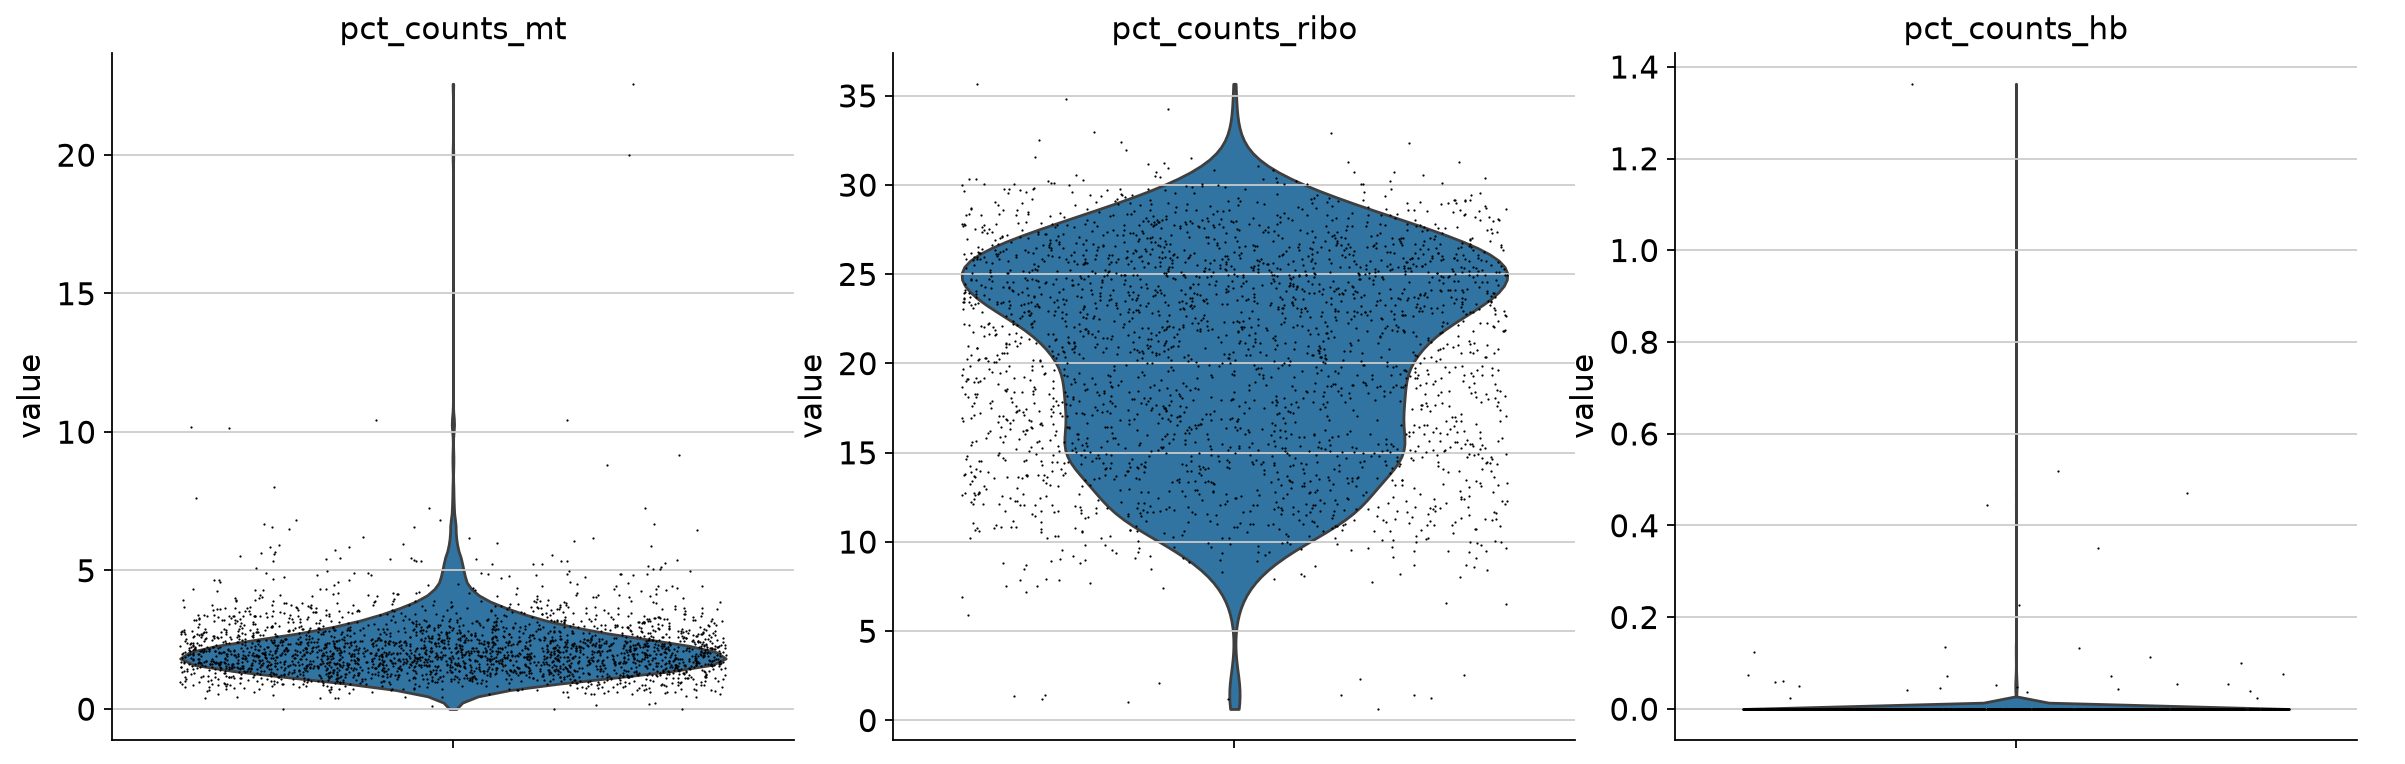

In [12]:
# LOG1P COUNT DISTRIBUTIONS -------------------------------------------------- #
sc.pl.violin(
    adata,
    ["pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"],
    jitter=0.4,
    multi_panel=True,
    show=False,
)
plt.savefig(experiment/'figures/qc_metrics/pbmc3k_mt_ribo_hb.png')

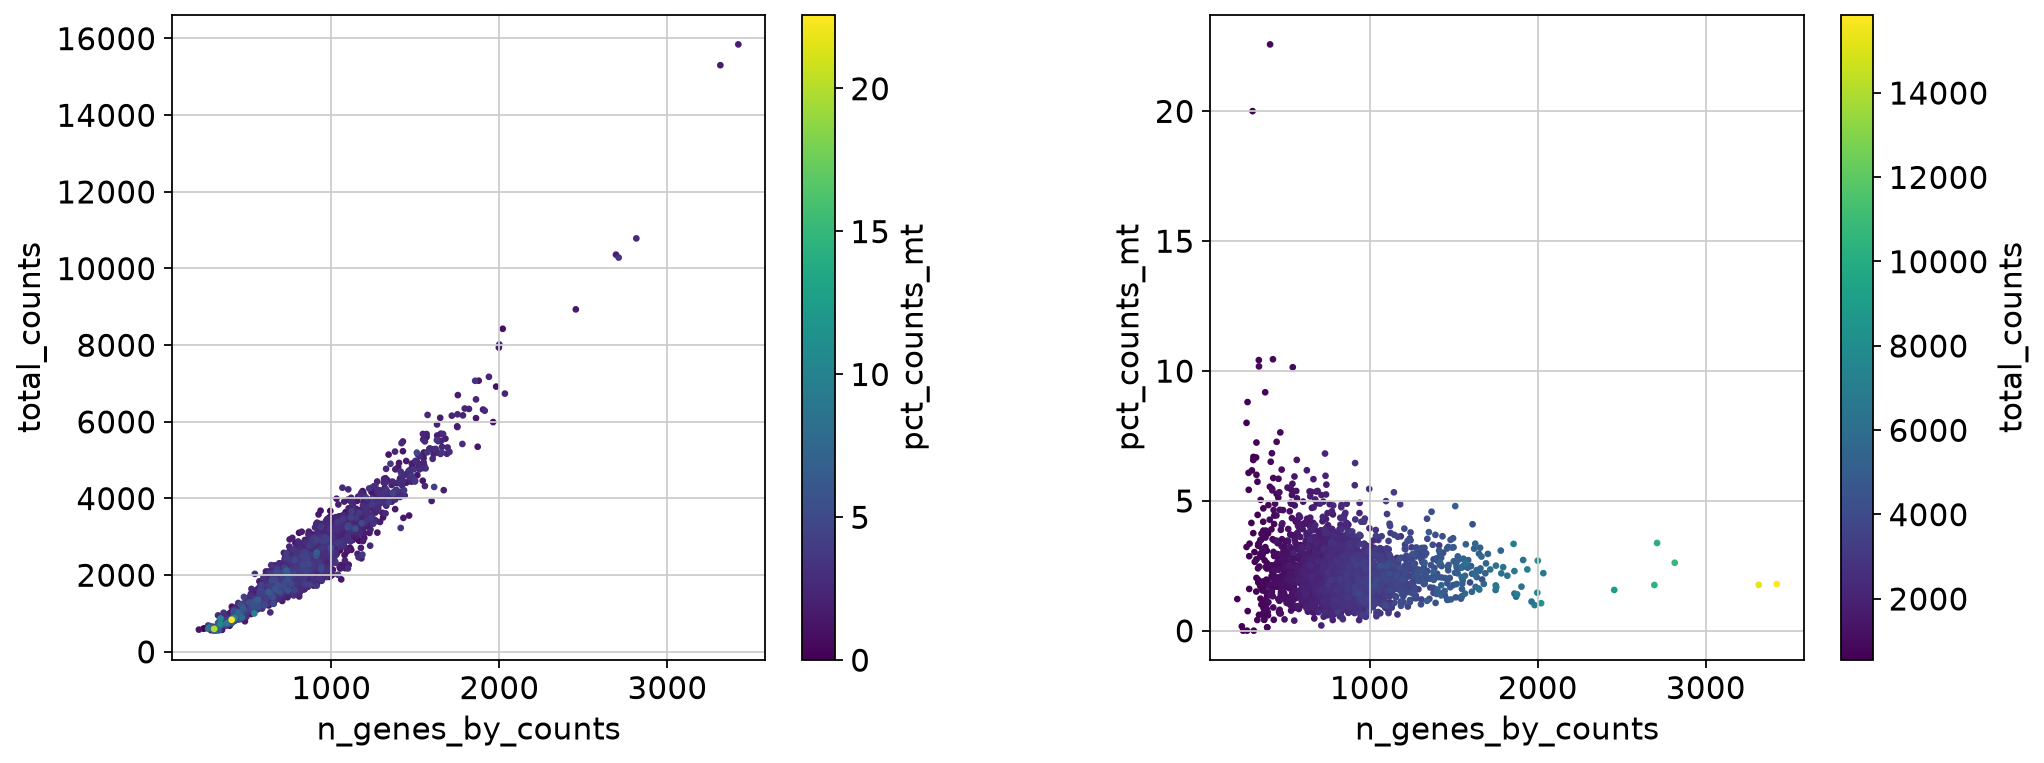

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
df1 = adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].sort_values("pct_counts_mt")

ax1.scatter(
    df1["n_genes_by_counts"], 
    df1["total_counts"], 
    c=df1["pct_counts_mt"], 
    cmap="viridis", 
    s=4, # Adjust point size
)
fig.colorbar(ax1.collections[0], ax=ax1, label='pct_counts_mt')
ax1.set_xlabel("n_genes_by_counts")
ax1.set_ylabel("total_counts")

df2 = adata.obs[["n_genes_by_counts", "pct_counts_mt", "total_counts"]].sort_values("total_counts")

ax2.scatter(
    df2["n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=df2["total_counts"], 
    cmap="viridis", 
    s=4,
)
fig.colorbar(ax2.collections[0], ax=ax2, label='total_counts')
ax2.set_xlabel("n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/qc_metrics/qc_metric_scatter_plots.png")
plt.show()

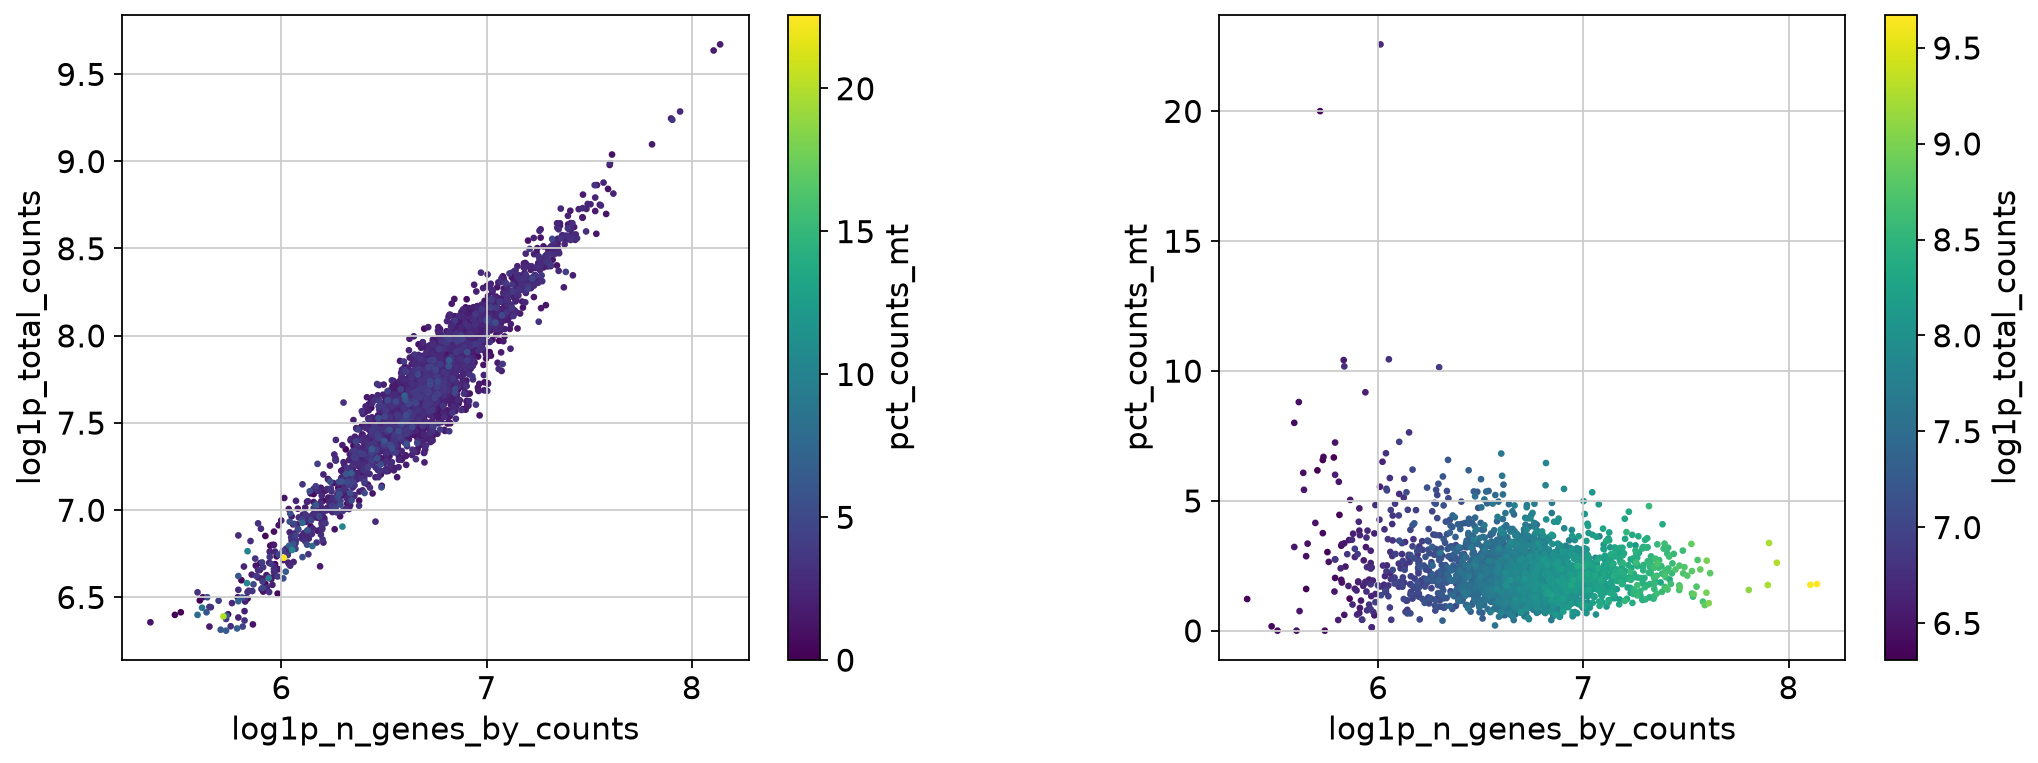

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
df1 = adata.obs[["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"]].sort_values("pct_counts_mt")

ax1.scatter(
    df1["log1p_n_genes_by_counts"], 
    df1["log1p_total_counts"], 
    c=df1["pct_counts_mt"], 
    cmap="viridis", 
    s=4, # Adjust point size
)
fig.colorbar(ax1.collections[0], ax=ax1, label='pct_counts_mt')
ax1.set_xlabel("log1p_n_genes_by_counts")
ax1.set_ylabel("log1p_total_counts")

df2 = adata.obs[["log1p_n_genes_by_counts", "pct_counts_mt", "log1p_total_counts"]].sort_values("log1p_total_counts")

ax2.scatter(
    df2["log1p_n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=df2["log1p_total_counts"], 
    cmap="viridis", 
    s=4,
)
fig.colorbar(ax2.collections[0], ax=ax2, label='log1p_total_counts')
ax2.set_xlabel("log1p_n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/qc_metrics/qc_metric_log1p_scatter_plots.png")
plt.show()

# Save data

In [15]:
adata.write(experiment/'results/pbmc3k_metrics.h5ad')